# Task 2: Apply a quantum Fourier transform $F$

Input: the basis state $|m\rangle$ from Task 1. Output: $F|m\rangle$, with $n = 6$ qubits and $d = 2^n = 64$.

$$F|m\rangle=\frac{1}{\sqrt d}\sum_{x=0}^{d-1}\zeta^{mx}\,|x\rangle,\qquad F_{x,m}=\frac{\zeta^{xm}}{\sqrt d},\qquad \zeta=e^{2\pi i/d}$$

Column $m$ of $F$ is the state $F|m\rangle$. Every amplitude has the same magnitude $1/\sqrt d$, and the phase of amplitude $x$ is $2\pi mx/d$, so $m$ acts as a frequency. After $F$ the message is carried only by the phases, which is what the key will act on in Task 3.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.quantum_info import Statevector, Operator
from qiskit.circuit.library import QFTGate

N = 6
d = 2**N
M = d
messages = list(range(M))

## Task 1 encoder (reference)

In [2]:
def ket(m, d):
    return Statevector.from_int(m, d)


def encode_message(m, n):
    """Return an n-qubit circuit preparing |m> from |0...0>."""
    if not (0 <= m < 2**n):
        raise ValueError(f"m={m} does not fit in n={n} qubits")

    qr = QuantumRegister(n, "msg")
    qc = QuantumCircuit(qr)

    for q in range(n):
        if (m >> q) & 1:
            qc.x(qr[q])

    return qc

In [3]:
def plot_circles(state, title="", cols=8, size=1.1):
    """Draw a state in the course's circle notation.

    For every basis state |j>:
      * grey outline  = the maximum possible magnitude (1)
      * filled disk   = radius proportional to |amplitude|  (so area ~ probability)
      * dark line     = the phase of the amplitude: phase 0 points straight UP and
                        the line rotates COUNTER-CLOCKWISE as the phase grows.
    """
    amps = np.asarray(state.data if hasattr(state, "data") else state, dtype=complex)
    d = len(amps)
    n = int(np.log2(d))
    cols = min(cols, d)
    rows = int(np.ceil(d / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 1.15))
    axes = np.atleast_1d(axes).ravel()
    for j, ax in enumerate(axes):
        ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15)
        ax.set_aspect("equal"); ax.axis("off")
        if j >= d:
            continue
        r = abs(amps[j])
        ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="0.6", lw=1))
        if r > 1e-9:
            ax.add_patch(plt.Circle((0, 0), r, color="#4a90d9", alpha=0.75))
            phi = np.angle(amps[j])
            ax.plot([0, -r * np.sin(phi)], [0, r * np.cos(phi)], color="#0b2545", lw=1.6)
        ax.set_title(f"|{j}>\n{j:0{n}b}", fontsize=7)
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()

## The QFT matrix and its properties

$F$ is built directly from the definition. It is unitary (a valid gate, inverted by $F^\dagger$) but not Hermitian, so applying $F$ again does not undo it: $F^2|m\rangle = |-m \bmod d\rangle$ and $F^4 = I$.

In [4]:
def dft_matrix(n):
    d = 2**n
    x = np.arange(d)
    return np.exp(2j * np.pi * np.outer(x, x) / d) / np.sqrt(d)


F = dft_matrix(N)
I = np.eye(d)

assert np.allclose(F.conj().T @ F, I)                       # unitary
assert not np.allclose(F.conj().T, F)                       # not Hermitian
assert all(np.allclose(F @ F @ ket(m, d).data, ket((-m) % d, d).data) for m in messages)
assert np.allclose(np.linalg.matrix_power(F, 4), I)          # F^4 = I
assert np.allclose(np.abs(F), 1 / np.sqrt(d))                # equal magnitudes

print("✅ F is unitary, not Hermitian, F^2|m> = |-m>, F^4 = I, all |F_xm| = 1/sqrt(d)")

✅ F is unitary, not Hermitian, F^2|m> = |-m>, F^4 = I, all |F_xm| = 1/sqrt(d)


## The QFT as a circuit

The QFT is built from H, controlled-phase and SWAP gates: going from the highest qubit down, apply H to qubit $j$, then a CPHASE of angle $\pi/2^{\,j-q}$ between $j$ and every lower qubit $q$, and finally reverse the qubit order with SWAPs. This uses $n$ H gates, $n(n-1)/2$ CPHASE gates and $\lfloor n/2\rfloor$ SWAPs, i.e. $O(n^2)$ gates.

In [5]:
def qft_manual(n):
    qc = QuantumCircuit(n, name="QFT")
    for j in reversed(range(n)):
        qc.h(j)
        for q in reversed(range(j)):
            qc.cp(np.pi / 2**(j - q), q, j)
    for i in range(n // 2):
        qc.swap(i, n - 1 - i)
    return qc


qft_circ = qft_manual(N)
print(qft_circ.draw("text", fold=-1))
print("gate counts:", dict(qft_circ.count_ops()))

                                                                                                                                                                        ┌───┐   
q_0: ───────────────────────────────────────────────────────────────────────■───────────────────────────■───────────────────────■─────────────────■─────────────■───────┤ H ├─X─
                                                                            │                           │                       │                 │       ┌───┐ │P(π/2) └───┘ │ 
q_1: ───────────────────────────────────────────────■───────────────────────┼─────────■─────────────────┼─────────■─────────────┼────────■────────┼───────┤ H ├─■─────────X───┼─
                                                    │                       │         │                 │         │       ┌───┐ │        │P(π/2)  │P(π/4) └───┘           │   │ 
q_2: ─────────────────────────────■─────────────────┼─────────■─────────────┼─────────┼────────■────────┼─────────┼

Both the hand-built circuit and Qiskit's `QFTGate` implement exactly the matrix $F$, so Qiskit uses the same $e^{+2\pi i mx/d}$ sign convention.

In [6]:
assert np.allclose(Operator(qft_circ).data, F)
assert np.allclose(Operator(QFTGate(N)).data, F)
print("✅ qft_manual(6) and QFTGate(6) both equal F")

✅ qft_manual(6) and QFTGate(6) both equal F


## Task 1 → Task 2: $|0\dots0\rangle \to |m\rangle \to F|m\rangle$

The encoder from Task 1 is followed by the QFT on all six qubits. The barrier marks where Task 1 ends.

In [7]:
def encode_and_qft(m, n):
    """Return an n-qubit circuit preparing F|m> from |0...0>."""
    qc = encode_message(m, n)
    qc.barrier()
    qc.append(QFTGate(n), range(n))
    return qc


m = 37
qc = encode_and_qft(m, N)
print(qc.draw("text"))

       ┌───┐ ░ ┌──────┐
msg_0: ┤ X ├─░─┤0     ├
       └───┘ ░ │      │
msg_1: ──────░─┤1     ├
       ┌───┐ ░ │      │
msg_2: ┤ X ├─░─┤2     ├
       └───┘ ░ │  Qft │
msg_3: ──────░─┤3     ├
             ░ │      │
msg_4: ──────░─┤4     ├
       ┌───┐ ░ │      │
msg_5: ┤ X ├─░─┤5     ├
       └───┘ ░ └──────┘


In [8]:
for m in messages:
    sv_m = Statevector.from_instruction(encode_and_qft(m, N))
    assert np.allclose(sv_m.data, F[:, m]), f"failed for m={m}"

print("✅ all", M, "messages mapped to F|m>")

✅ all 64 messages mapped to F|m>


## Circle notation: before and after $F$

$|37\rangle$ has all its weight on one basis state. After $F$ every circle has the same size ($1/\sqrt{64}$, probability $1/64$), and the phase line turns by $360°\cdot 37/64$ from one basis state to the next.

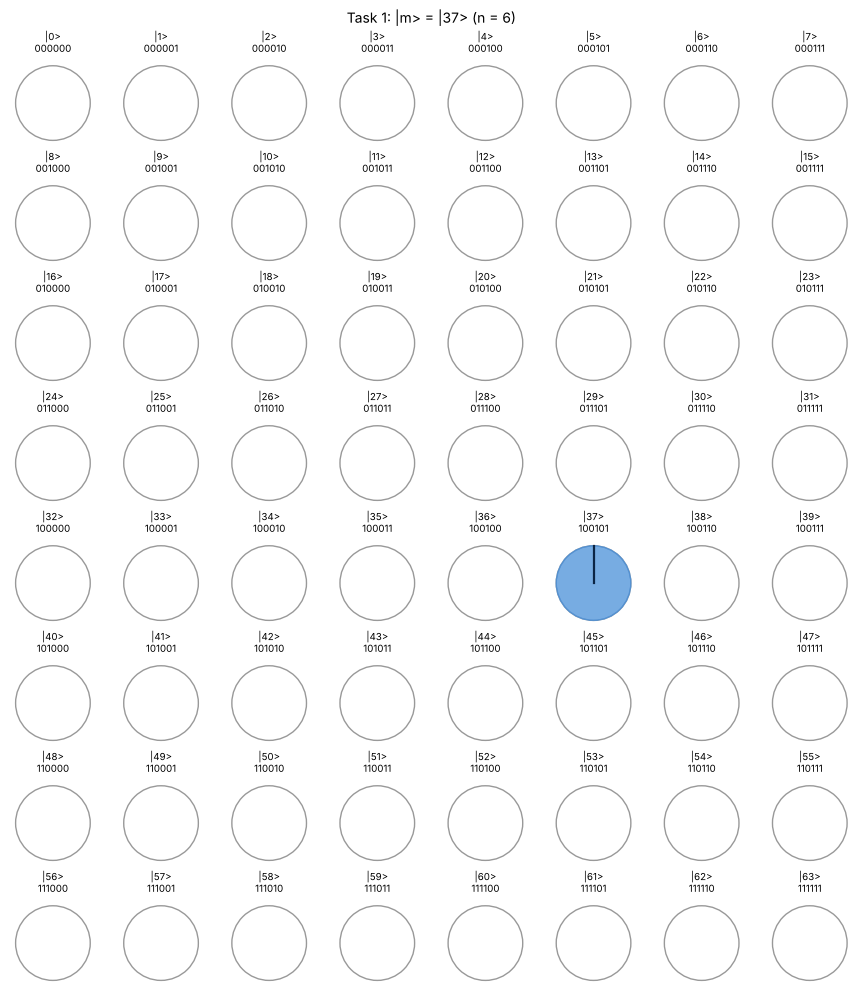

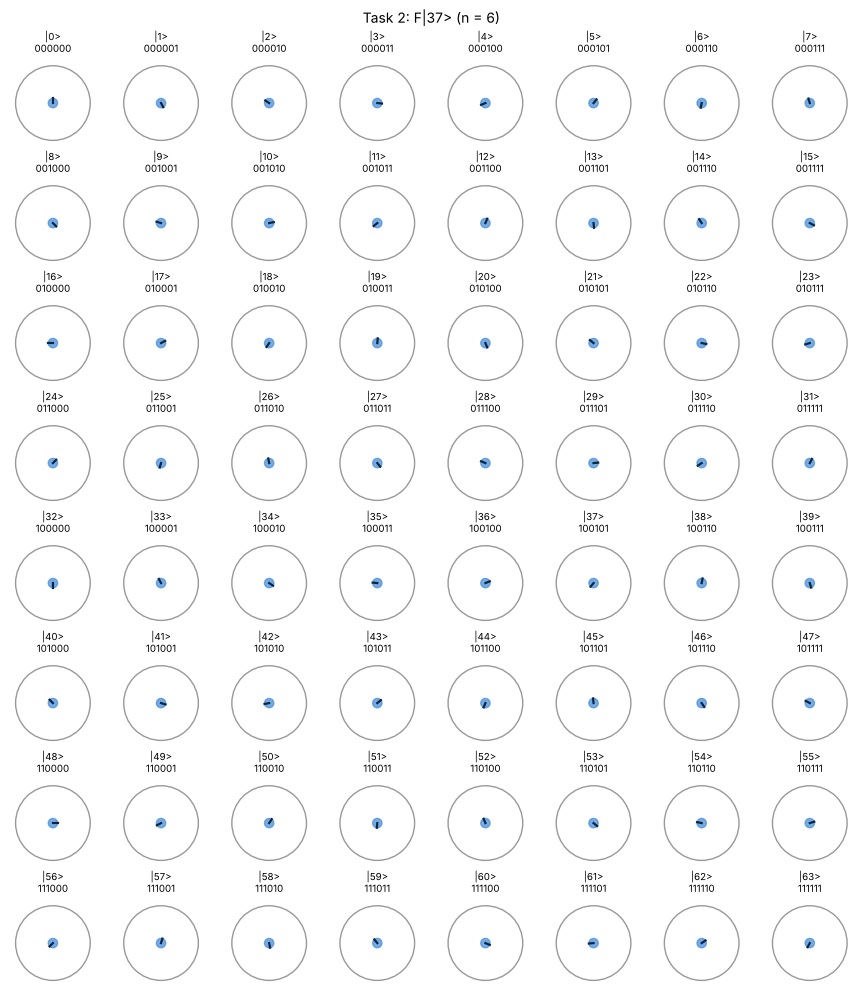

In [9]:
m = 37
plot_circles(Statevector.from_instruction(encode_message(m, N)), "Task 1: |m> = |37> (n = 6)")
plot_circles(Statevector.from_instruction(encode_and_qft(m, N)), "Task 2: F|37> (n = 6)")

In [10]:
probs = Statevector.from_instruction(encode_and_qft(37, N)).probabilities()
print("min / max outcome probability:", probs.min().round(6), probs.max().round(6), " (1/64 =", round(1/64, 6), ")")

min / max outcome probability: 0.015625 0.015625  (1/64 = 0.015625 )


## $F$ alone does not hide the message

A measurement of $F|m\rangle$ gives a uniformly random outcome, but $F$ is public: applying $F^\dagger$ (`QFTGate(n).inverse()`) recovers $m$ for every message. Hiding the message therefore needs a secret key phase applied after $F$, which is Task 3.

In [11]:
for m in messages:
    qc_eve = encode_and_qft(m, N)
    qc_eve.append(QFTGate(N).inverse(), range(N))
    probs = Statevector.from_instruction(qc_eve).probabilities_dict()
    assert int(max(probs, key=probs.get), 2) == m

print("✅ F^dagger recovers every message: F by itself is not a lock")

✅ F^dagger recovers every message: F by itself is not a lock
